# Decaimiento de la discriminación, fuga, monotonicidad rota y concentración

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 03 de este tema (la tasa, el tamaño de cada prueba, la escalera de potencia)
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este cuaderno puedes:

- leer la potencia de la prueba del BCE del AUC frente al AUC de desarrollo y de la prueba de DeLong a lo largo de una escalera de caídas de AUC, y ver cuánto puede detectar una prueba con 150 incumplidos;
- mostrar que la prueba de AUC del BCE trata el AUC de desarrollo como conocido, medir cuánto sobrerrechaza cuando ese AUC se estimó, y comprobar que sumar la varianza de desarrollo mantiene el tamaño;
- medir qué ven las pruebas de discriminación y de estabilidad de una variable filtrada, y por qué la prueba de DeLong casi nunca rechaza sobre modelos anidados ajustados con la muestra de comparación (2 rechazos en 1.000, frente al 0,001 que reportan Demler et al.);
- plantar una monotonicidad rota en una matriz de migración y en una curva de PD y leer la potencia de las pruebas z de migración y de la prueba del perfil de incumplimiento;
- mostrar que el estadístico de concentración del BCE está acotado bajo su valor crítico con diez grados, de modo que no puede rechazar por muy concentrados que queden los grados, y compararlo con el chi-cuadrado de los conteos.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son cuatro familias del caso C22 (validar al validador), cada una de las cuales planta un defecto de severidad conocida en datos sorteados de un generador de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`). Las escaleras de severidad son elecciones de diseño de Contraste; ninguna es una afirmación sobre un banco.

| Familia | Defecto plantado | Pruebas a las que apunta |
|---|---|---|
| `discrimination-decay` | el AUC actual cae bajo el AUC de desarrollo de 0,80, entre 0 y 0,08 | la prueba de AUC del BCE, DeLong |
| `leakage` | una variable lleva el resultado en desarrollo y es ruido al decidir | la prueba de AUC, el CSI, DeLong en modelos anidados |
| `broken-monotonicity` | una celda de migración a dos escalones de la diagonal es más frecuente que su vecina; las PD de dos grados se cruzan | las pruebas z de migración, la prueba del perfil de incumplimiento |
| `concentration` | una fracción de la masa de cada grado se mueve al grado modal | la prueba de concentración del BCE, el chi-cuadrado de los conteos |

- **Archivos que se leen:** `data/derived/C22/discrimination-decay.json`, `leakage.json`, `broken-monotonicity.json` y `concentration.json`: en cada uno, `outputs.simulations` (las tasas con sus errores de Monte Carlo), `outputs.generators` (configuración y verdad), `outputs.ladder` e `impact`; el archivo de fuga guarda además la tasa publicada de Demler et al. en `outputs.golden`, y el de concentración el estadístico acotado en `outputs.exact_curves`.

La celda siguiente carga los cuatro artefactos e imprime su versión del motor y su tamaño.

In [2]:
# Cargar las cuatro familias e indexar sus simulaciones por familia y clave
LANG = "es"
ROOT = Path("../../..").resolve()
names = ("discrimination-decay", "leakage", "broken-monotonicity", "concentration")
families = {name: json.loads((ROOT / "data" / "derived" / "C22" / f"{name}.json").read_text(encoding="utf-8")) for name in names}
rows = {name: {row["key"]: row for row in fam["outputs"]["simulations"]} for name, fam in families.items()}
decay, leak, mono, conc = (families[name] for name in names)

for name in names:
    fam = families[name]
    print(f"{name:22s} calculado por riskvalidation {fam['provenance']['riskvalidation_version']} | {len(rows[name]):2d} simulaciones | escalera: {fam['outputs']['ladder']['label'][LANG]}")
print("instalado:", rv.__version__)

discrimination-decay   calculado por riskvalidation 0.4.3 | 21 simulaciones | escalera: caída de AUC
leakage                calculado por riskvalidation 0.4.3 | 14 simulaciones | escalera: filtración (desplazamiento de la variable para incumplidos)
broken-monotonicity    calculado por riskvalidation 0.4.3 | 24 simulaciones | escalera: celda plantada / vecina más cercana
concentration          calculado por riskvalidation 0.4.3 | 12 simulaciones | escalera: fracción movida al grado modal
instalado: 0.8.1


## Método

**La prueba de AUC del BCE.** Con AUC$_\text{ini}$ el AUC de desarrollo y AUC$_\text{act}$ el actual, el BCE trata el valor de desarrollo como un número conocido y prueba

$$S = \frac{\mathrm{AUC}_\text{ini} - \mathrm{AUC}_\text{act}}{s}, \qquad p = 1 - \Phi(S)$$

con $s^2$ la varianza del BCE del AUC actual (ECB 2019, sección 2.5.4.1 y Anexo 3.1). Cuando el AUC de desarrollo se estimó con una muestra independiente de la actual, `disc_auc_vs_initial` del motor acepta su varianza y usa $s^2 + s^2_\text{ini}$, una extensión de la fórmula del BCE que el resultado declara. Los generadores binormales tienen AUC conocido, $\Phi(\delta/\sqrt 2)$ para una separación $\delta$ (Hanley y McNeil, 1982).

**La prueba de DeLong** compara dos AUC puntuados sobre los mismos deudores y es bilateral; su derivación supone que los parámetros del modelo son conocidos, lo que falla para modelos anidados ajustados con la muestra de comparación (Demler, Pencina y D'Agostino, 2012).

**Las pruebas z de migración** comparan cada celda fuera de la diagonal $p_{ij}$ de una matriz de migración con su vecina más cercana a la diagonal, $p_{i,j'}$, con $z = (p_{ij'} - p_{ij})/\sqrt{\mathrm{Var}}$; el motor informa el menor valor p ajustado por Holm sobre todas las celdas, porque el BCE no especifica control de pruebas múltiples.

**La prueba de concentración del BCE** compara el coeficiente de variación de las frecuencias por grado con su valor de desarrollo:

$$S = \frac{\sqrt{K-1}\,(\mathrm{CV}_\text{act} - \mathrm{CV}_\text{ini})}{\sqrt{\mathrm{CV}_\text{act}^2\,(0{,}5 + \mathrm{CV}_\text{act}^2)}}, \qquad p = 1 - \Phi(S)$$

La prueba del perfil de incumplimiento, que compara la forma de la curva de PD con la forma que implican las PD, se describe en el cuaderno 03 (Tasche, 2013). Los pasos recorren las cuatro familias por turno, cada una con un conjunto, la tabla de potencia y la repetición de una fila versionada.

### Parte A, paso 1: qué tan grande es la caída de AUC que se detecta

La familia `discrimination-decay` baja el AUC actual desde el valor de desarrollo de 0,80 en 0 a 0,08, con 150 incumplidos y 4.850 sobrevivientes. La prueba del BCE conoce exactamente el AUC de desarrollo; DeLong compara un campeón de 0,80 con un retador de menor AUC sobre los mismos deudores. La celda siguiente imprime la tasa al 5% de ambas a lo largo de la escalera, e interpola la caída que cada una detecta con 80% de potencia, para compararla con los números principales del caso.

In [3]:
# Imprimir la potencia de la prueba de AUC del BCE y de DeLong a lo largo de la escalera de caídas de AUC e interpolar la caída detectada con 80% de potencia
drops = decay["outputs"]["ladder"]["values"]
ecb_power = [rows["discrimination-decay"][f"disc.auc_vs_initial@d{x:g}"]["rates"]["p<0.05"]["rate"] for x in drops]
delong_power = [rows["discrimination-decay"][f"disc.delong@d{x:g}"]["rates"]["p<0.05"]["rate"] for x in drops]
print(f"{'caída de AUC':>12s} {'prueba BCE':>11s} {'DeLong':>8s}")
for x, a, b in zip(drops, ecb_power, delong_power):
    print(f"{x:12.2f} {a:11.3f} {b:8.3f}")
print("caída detectada con 80% de potencia, prueba BCE:", round(float(np.interp(0.8, ecb_power, drops)), 4), "|", "versionado:", round(decay["impact"]["ecb_drop80"]["value"], 4))
print("caída detectada con 80% de potencia, DeLong:", round(float(np.interp(0.8, delong_power, drops)), 4), "|", "versionado:", round(decay["impact"]["delong_drop80"]["value"], 4))

caída de AUC  prueba BCE   DeLong
        0.00       0.029    0.049
        0.01       0.116    0.081
        0.02       0.255    0.180
        0.03       0.462    0.342
        0.05       0.815    0.716
        0.08       0.991    0.978
caída detectada con 80% de potencia, prueba BCE: 0.0492 | versionado: 0.0492
caída detectada con 80% de potencia, DeLong: 0.0596 | versionado: 0.0596


### Parte A, paso 2: un conjunto de cada prueba

El generador del peldaño `d0.05` sortea puntajes con un AUC actual de 0,75 frente a un AUC de desarrollo de 0,80, y el generador de pares sortea un campeón y un retador con la misma brecha de 0,05. La celda siguiente reconstruye ambos desde la configuración versionada, sortea un conjunto de cada uno y corre las pruebas del motor, como las correría un validador con una muestra.

In [4]:
# Reconstruir los generadores del peldaño 0,05 desde la configuración versionada, sortear un conjunto de cada uno y correr las dos pruebas
from riskvalidation.generators import BinormalScores
from riskvalidation.validation import disc_auc_vs_initial, disc_delong

gens = decay["outputs"]["generators"]
single = BinormalScores(**gens["binormal-150-d0.05"]["config"])
pair = BinormalScores(**gens["binormal-150-pair-d0.05"]["config"])
print("AUC actual verdadera:", round(gens["binormal-150-d0.05"]["truth"]["auc_current"], 4), "|", "AUC de desarrollo:", round(gens["binormal-150-d0.05"]["truth"]["auc_development"], 4))

sample = single.draw(np.random.default_rng(8))
ecb_result = disc_auc_vs_initial(sample["auc_initial"], sample["risk"], sample["defaults"])
print("prueba BCE: AUC estimado", round(ecb_result.extras["auc_current"], 4), "| S", round(ecb_result.statistic, 3), "|", "valor p", round(ecb_result.p_value, 4))

both = pair.draw(np.random.default_rng(8))
delong_result = disc_delong(both["risk_1"], both["risk_2"], both["defaults"])
print("DeLong:", "estadístico", round(delong_result.statistic, 3), "|", "valor p", round(delong_result.p_value, 4))

AUC actual verdadera: 0.75 | AUC de desarrollo: 0.8
prueba BCE: AUC estimado 0.7336 | S 3.2 | valor p 0.0007
DeLong: estadístico 2.435 | valor p 0.0149


### Parte A, paso 3: el AUC de desarrollo también es una estimación

En la práctica el AUC de desarrollo se estimó con una muestra de desarrollo, así que lleva su propio error. La forma del BCE lo ignora. El panel `development` mide el tamaño de la prueba cuando nada cambió y el AUC de desarrollo se estimó con una muestra de un tamaño dado respecto de la actual (la primera columna es la razón de la muestra actual a la de desarrollo, 0 cuando el AUC es conocido), en la forma del BCE y con la varianza de desarrollo sumada. La celda siguiente imprime ambas a lo largo del panel.

In [5]:
# Imprimir el tamaño de la prueba de AUC del BCE cuando nada cambió, según el tamaño de la muestra de desarrollo, en la forma del BCE y extendida
dev_axis = decay["outputs"]["panels"][2]["axis"][LANG]
print("eje x:", dev_axis)
print(f"{'x':>6s} {'forma BCE':>10s} {'extendida':>10s}")
for tag in ("m0", "m16", "m4", "m1", "m0.467"):
    row = rows["discrimination-decay"][f"disc.auc_vs_initial@{tag}"]
    extended = rows["discrimination-decay"].get(f"disc.auc_vs_initial@{tag}-extended")
    shown = f"{extended['rates']['p<0.05']['rate']:10.4f}" if extended else f"{'-':>10s}"
    print(f"{row['x']:6.3f} {row['rates']['p<0.05']['rate']:10.4f} {shown}")
print("resultado principal, tamaño con la razón de los tramos de C01:", decay["impact"]["ecb_size_c01_ratio"]["value"])

eje x: muestra actual / de desarrollo (0: AUC conocida)
     x  forma BCE  extendida
 0.000     0.0423          -
 0.062     0.0452     0.0387
 0.250     0.0633     0.0450
 1.000     0.1120     0.0558
 2.141     0.1703     0.0530
resultado principal, tamaño con la razón de los tramos de C01: 0.17025


La celda siguiente repite una fila versionada desde su semilla, la forma extendida con tamaños de muestra iguales (unos diez segundos). La forma extendida necesita la varianza del AUC de desarrollo, que el generador devuelve con cada sorteo; la función de alimentación se la pasa a la prueba. La forma del BCE con los mismos tamaños de muestra se lee de la tabla anterior.

In [6]:
# Repetir la forma extendida con tamaños de muestra iguales desde su semilla versionada
from riskvalidation.harness import simulate

dev_generator = BinormalScores(**gens["binormal-150-m1"]["config"])
extended_feed = lambda d: {"auc_initial": d["auc_initial"], "risk": d["risk"], "defaults": d["defaults"], "auc_initial_variance": d["development_auc_variance"]}
key = "disc.auc_vs_initial@m1-extended"
row = rows["discrimination-decay"][key]
replay = simulate("disc.auc_vs_initial", dev_generator, n_rep=row["n_rep"], seed=row["seed"], feed=extended_feed)
print(f"{key:34s} | repetición {replay.rates['p<0.05'].rejections} | versionado {row['rates']['p<0.05']['rejections']} | tamaño {replay.rates['p<0.05'].rate:.4f}")

disc.auc_vs_initial@m1-extended    | repetición 223 | versionado 223 | tamaño 0.0558


### Parte B, paso 4: qué le hace una fuga a las pruebas

En la familia `leakage` una variable se desplaza para los incumplidos en la medida de la fuga $\lambda$ en desarrollo y no al decidir, de modo que el AUC del modelo queda inflado en desarrollo y cae cuando la fuga desaparece. El artefacto guarda los AUC exactos de desarrollo y actual de cada peldaño, y la tasa a la que disparan la prueba de AUC y el CSI de la variable filtrada. La celda siguiente los imprime, con la inflación del AUC $\mathrm{AUC}_\text{des} - \mathrm{AUC}_\text{act}$.

In [7]:
# Imprimir la inflación exacta del AUC de cada fuga y la tasa a la que disparan la prueba de AUC y el CSI
leaks = leak["outputs"]["ladder"]["values"]
print(f"{'fuga':>5s} {'AUC desarrollo':>15s} {'AUC actual':>12s} {'inflación':>10s} {'prueba AUC':>11s} {'CSI':>6s}")
for lam in leaks:
    truth = leak["outputs"]["generators"][f"binormal-150-leak{lam:g}"]["truth"]
    auc_rate = rows["leakage"][f"disc.auc_vs_initial@l{lam:g}"]["rates"]["p<0.05"]["rate"]
    csi_rate = rows["leakage"][f"stability.csi@l{lam:g}"]["rates"]["p<0.05"]["rate"]
    print(f"{lam:5.2f} {truth['auc_development']:15.4f} {truth['auc_current']:12.4f} {truth['auc_development'] - truth['auc_current']:10.4f} {auc_rate:11.3f} {csi_rate:6.3f}")
print("resultado principal, inflación con una fuga de 1:", round(leak["impact"]["dev_auc_inflation_l1"]["value"], 4))

 fuga  AUC desarrollo   AUC actual  inflación  prueba AUC    CSI
 0.00          0.6915       0.6915     0.0000       0.046  0.046
 0.25          0.7340       0.6915     0.0426       0.635  0.060
 0.50          0.7734       0.6915     0.0819       0.989  0.079
 1.00          0.8413       0.6915     0.1499       1.000  0.146
 1.50          0.8944       0.6915     0.2029       1.000  0.334
 2.00          0.9332       0.6915     0.2417       1.000  0.581
resultado principal, inflación con una fuga de 1: 0.1499


### Parte B, paso 5: DeLong en modelos anidados

Demler, Pencina y D'Agostino (2012) muestran que cuando el segundo modelo agrega al primero un predictor sin efecto y ambos se ajustan con la muestra que usa la prueba, la distribución nula del estadístico de DeLong no es normal y la prueba rechaza mucho menos que su nivel. Su simulación (datos tipo Framingham, 8.261 observaciones de las cuales 621 casos, 1.000 repeticiones) encontró 0,001 al nivel de 5%. El generador `NestedLda` reproduce el diseño. La celda siguiente repite la fila versionada desde su semilla (unos cinco segundos), compara el conteo con la tasa publicada mediante `agrees_with_published`, e imprime la comparación no anidada, dos puntajes independientes de igual AUC sobre una muestra independiente, donde la prueba debería mantener su nivel.

In [8]:
# Repetir la fila de DeLong anidado, compararla con la tasa publicada e imprimir la comparación no anidada
from riskvalidation.generators import NestedLda
from riskvalidation.harness import Rate, agrees_with_published

leak_gens = leak["outputs"]["generators"]
nested_row = rows["leakage"]["disc.delong@nested"]
replay = simulate("disc.delong", NestedLda(**leak_gens["nested-lda-framingham"]["config"]), n_rep=nested_row["n_rep"], seed=nested_row["seed"])
print("modelos anidados, repetición:", replay.rates["p<0.05"].rejections, "de", replay.n_rep, "|", "versionado:", nested_row["rates"]["p<0.05"]["rejections"])

study = leak["outputs"]["golden"][0]
cell = study["cells"][0]
ok, z = agrees_with_published(Rate(replay.rates["p<0.05"].rejections, replay.n_rep), cell["published"], study["runs_published"])
print("tasa publicada (Demler et al.):", cell["published"], "|", "medida:", replay.rates["p<0.05"].rate, "| z", round(z, 2), "|", "concuerda:", ("sí" if ok else "no"))

non_nested = rows["leakage"]["disc.delong@non-nested"]["rates"]["p<0.05"]
print("puntajes no anidados, muestra independiente:", round(non_nested["rate"], 4), "(SE", round(non_nested["se"], 4), ")")
print("Cita traducida: «el nivel de significancia de la prueba F es cercano al nivel nominal de 0.05, mientras que es 0.001 para la prueba de DeLong».")

modelos anidados, repetición: 2 de 1000 | versionado: 2
tasa publicada (Demler et al.): 0.001 | medida: 0.002 | z 0.58 | concuerda: sí
puntajes no anidados, muestra independiente: 0.0525 (SE 0.005 )
Cita traducida: «el nivel de significancia de la prueba F es cercano al nivel nominal de 0.05, mientras que es 0.001 para la prueba de DeLong».


### Parte C, paso 6: la monotonicidad plantada

Una matriz de migración no debería tener una celda a dos escalones de la diagonal más frecuente que su vecina más cercana. El generador toma una matriz decreciente de siete grados y fija una celda, del grado 4 al grado 2, en un múltiplo de su vecina, del grado 4 al grado 3. La celda siguiente construye la matriz base y la plantada con `decaying_matrix` y `break_monotonicity` del motor e imprime la fila que cambia.

In [9]:
# Construir la matriz de migración base y la plantada e imprimir la fila del grado 4
from riskvalidation.generators import break_monotonicity, decaying_matrix

base = decaying_matrix(7)
planted = break_monotonicity(base, 3, 1, 2.0)
print("fila del grado 4, base:     ", np.round(base[3], 4))
print("fila del grado 4, plantada:", np.round(planted[3], 4))
print("celda 4 a 2 sobre su vecina, 4 a 3:", round(float(planted[3, 1] / planted[3, 2]), 3))
committed_matrix = np.array(mono["outputs"]["generators"]["migrations-7-500-r2"]["config"]["matrix"])
print("igual a la matriz versionada:", ("sí" if np.allclose(planted, committed_matrix) else "no"))

fila del grado 4, base:      [0.0143 0.0286 0.0571 0.8    0.0571 0.0286 0.0143]
fila del grado 4, plantada: [0.0143 0.1143 0.0571 0.7143 0.0571 0.0286 0.0143]
celda 4 a 2 sobre su vecina, 4 a 3: 2.0
igual a la matriz versionada: sí


### Parte C, paso 7: las pruebas z en una muestra, y su potencia

La celda siguiente sortea 500 deudores por grado de la matriz plantada y corre `rating_migration_ztests`. El estadístico es el número de celdas cuyo valor p crudo es menor que 5%, el valor p es el menor ajustado por Holm, y la celda con el menor valor p ajustado es la plantada, que la prueba encuentra solo con los conteos. Luego repite la fila versionada para la razón de 2 con 500 deudores por grado, e imprime la potencia de la prueba por razón para 500 y 2.000 deudores por grado.

In [10]:
# Sortear una muestra de la matriz plantada, correr las pruebas z de migración, repetir la fila versionada e imprimir la potencia por razón
from riskvalidation.generators import Migrations
from riskvalidation.validation import rating_migration_ztests

mono_gens = mono["outputs"]["generators"]
migrations = Migrations(**mono_gens["migrations-7-500-r2"]["config"])
counts = migrations.draw(np.random.default_rng(3))["counts"]
result = rating_migration_ztests(counts)
worst = min(result.extras["cells"], key=lambda cell: cell["p_holm"])
print("celdas con valor p crudo bajo 5%:", int(result.statistic), "|", "menor valor p ajustado por Holm:", f"{result.p_value:.2e}")
print("celda con el menor p ajustado: grado", worst["from"], "a grado", worst["to"], "| z", round(float(worst["z"]), 2))

row = rows["broken-monotonicity"]["rating.migration_ztests@r2-n500"]
replay = simulate("rating.migration_ztests", migrations, n_rep=row["n_rep"], seed=row["seed"])
print("repetición de la fila de razón 2:", replay.rates["p<0.05"].rejections, "|", "versionado:", row["rates"]["p<0.05"]["rejections"])

ratios = mono["outputs"]["ladder"]["values"]
print(f"{'razón':>6s} {'500':>8s} {'2000':>8s}   ({'potencia al 5%, deudores por grado'})")
for r in ratios:
    print(f"{r:6.2f} " + " ".join(f"{rows['broken-monotonicity'][f'rating.migration_ztests@r{r:g}-n{n}']['rates']['p<0.05']['rate']:8.3f}" for n in (500, 2000)))

celdas con valor p crudo bajo 5%: 1 | menor valor p ajustado por Holm: 4.06e-04
celda con el menor p ajustado: grado 4 a grado 2 | z -4.27
repetición de la fila de razón 2: 1110 | versionado: 1110
 razón      500     2000   (potencia al 5%, deudores por grado)
  1.00    0.001    0.001
  1.25    0.013    0.096
  1.50    0.079    0.657
  2.00    0.555    1.000
  3.00    0.997    1.000
  4.00    1.000    1.000


### Parte C, paso 8: dos PD cruzadas

El segundo defecto de la familia conserva el nivel de la curva de PD y rompe su orden: las PD verdaderas de los grados 3 y 4 se acercan y se cruzan en una fracción $s$ (0 sin cambio, 1 intercambiadas), y a las pruebas se les da las PD originales. La prueba del perfil de incumplimiento mira la forma, así que debería ver este defecto donde era ciega a un nivel. La celda siguiente imprime su potencia a lo largo del cruce, junto al chi-cuadrado por grados, y reconstruye las PD intercambiadas desde la configuración versionada.

In [11]:
# Imprimir las PD verdaderas y aplicadas del peldaño intercambiado y la potencia de las pruebas del perfil y chi-cuadrado a lo largo del cruce
swap_config = mono_gens["grades-7-swap1"]["config"]
print("PD aplicadas:", swap_config["pd_forecast"][0])
print("PD verdaderas:", swap_config["pd_true"][0])
swaps = (0.0, 0.2, 0.4, 0.6, 0.8, 1.0)
print(f"{'s':>5s} {'perfil de incumpl.':>19s} {'chi-cuadrado':>12s}")
for s in swaps:
    profile = rows["broken-monotonicity"][f"pd.default_profile@swap{s:g}"]["rates"]["p<0.05"]["rate"]
    chi2 = rows["broken-monotonicity"][f"pd.chi2_grades@swap{s:g}"]["rates"]["p<0.05"]["rate"]
    print(f"{s:5.1f} {profile:19.3f} {chi2:12.3f}")

PD aplicadas: [0.002, 0.005, 0.01, 0.02, 0.04, 0.08, 0.16]
PD verdaderas: [0.002, 0.005, 0.02, 0.01, 0.04, 0.08, 0.16]
    s  perfil de incumpl. chi-cuadrado
  0.0               0.044        0.056
  0.2               0.095        0.090
  0.4               0.232        0.226
  0.6               0.536        0.493
  0.8               0.787        0.769
  1.0               0.952        0.937


### Parte D, paso 9: un estadístico acotado

La familia `concentration` mueve una fracción de la masa de cada grado al grado modal de diez grados. El estadístico de la prueba de concentración del BCE depende solo de las frecuencias por grado, a través de sus coeficientes de variación, y no del número de deudores. Su mayor valor posible depende entonces solo de las frecuencias de desarrollo. La celda siguiente lee esas frecuencias desde el generador versionado, evalúa `rating_hhi` del motor sobre una grilla de 401 fracciones de 0 a 1 e imprime el mayor estadístico y el valor p que da, junto al valor crítico de 1,645.

In [12]:
# Evaluar la prueba de concentración del BCE sobre una grilla de fracciones movidas al grado modal y encontrar el mayor estadístico
from riskvalidation.generators import concentrate
from riskvalidation.validation.rating_system import concentration, rating_hhi

initial = np.array(conc["outputs"]["generators"]["grades-10-c0.5"]["config"]["initial"])
cv_initial, hi_initial = concentration(initial)
shares = np.linspace(0.0, 1.0, 401)
statistics = np.array([rating_hhi(concentrate(initial, s), initial).statistic for s in shares])
best = int(np.argmax(statistics))
print("frecuencias de desarrollo:", initial.tolist(), "| CV", round(cv_initial, 4))
print("mayor estadístico:", round(float(statistics[best]), 4), "con la fracción", shares[best], "|", "resultado principal versionado:", round(conc["impact"]["hhi_max_statistic"]["value"], 4))
print("menor valor p que puede dar:", round(float(stats.norm.sf(statistics.max())), 4), "|", "valor crítico al 5%:", round(float(stats.norm.isf(0.05)), 4))
print("estadístico con toda la masa en el grado modal (fracción 1):", round(float(statistics[-1]), 4))

frecuencias de desarrollo: [0.02, 0.05, 0.1, 0.15, 0.2, 0.18, 0.13, 0.09, 0.05, 0.03] | CV 0.6017
mayor estadístico: 1.0913 con la fracción 0.3725 | resultado principal versionado: 1.0913
menor valor p que puede dar: 0.1376 | valor crítico al 5%: 1.6449
estadístico con toda la masa en el grado modal (fracción 1): 0.7781


### Parte D, paso 10: qué configuraciones pueden rechazar, y cómo se compara con el chi-cuadrado

El artefacto guarda el estadístico como función del coeficiente de variación actual para cuatro configuraciones: diez grados con CV inicial de 0,3, 0,6 y 1,0, y veintiséis grados con 0,6. La celda siguiente imprime el mayor valor de cada una, para ver cuáles pueden cruzar 1,645, y luego la potencia de la prueba del BCE y de la prueba chi-cuadrado de homogeneidad sobre los conteos por grado a lo largo de la escalera de fracciones movidas.

In [13]:
# Imprimir el mayor valor de cada curva del estadístico versionada y la potencia de la prueba del BCE y del chi-cuadrado a lo largo de la escalera
critical_value = stats.norm.isf(0.05)
for series in conc["outputs"]["exact_curves"][0]["series"]:
    top = max(y for y in series["y"] if y is not None)
    grades_k, cv_initial_k = series["id"][1:].split("-cv")
    print(f"{grades_k:>3s} grados, CV inicial {cv_initial_k:4s} mayor estadístico {top:.3f} | puede superar 1.645: {'sí' if top > critical_value else 'no'}")

moved = conc["outputs"]["ladder"]["values"]
print(f"{'fracción movida':>14s} {'prueba BCE':>11s} {'chi-cuadrado':>12s}")
for s in moved:
    hhi_rate = rows["concentration"][f"rating.hhi@c{s:g}"]["rates"]["p<0.05"]["rate"]
    chi2_rate = rows["concentration"][f"stability.chi2@c{s:g}"]["rates"]["p<0.05"]["rate"]
    print(f"{s:14.2f} {hhi_rate:11.3f} {chi2_rate:12.3f}")

 10 grados, CV inicial 0.3  mayor estadístico 1.756 | puede superar 1.645: sí
 10 grados, CV inicial 0.6  mayor estadístico 1.094 | puede superar 1.645: no
 10 grados, CV inicial 1    mayor estadístico 0.709 | puede superar 1.645: no
 26 grados, CV inicial 0.6  mayor estadístico 1.823 | puede superar 1.645: sí
fracción movida  prueba BCE chi-cuadrado
          0.00       0.000        0.053
          0.01       0.000        0.082
          0.02       0.000        0.234
          0.05       0.000        0.948
          0.10       0.000        1.000
          0.50       0.000        1.000


### Paso 11: las cuatro curvas de potencia, dibujadas

La última celda dibuja un panel por familia: la prueba de AUC del BCE y DeLong frente a la caída de AUC, la prueba de AUC y el CSI frente a la fuga, las pruebas z de migración frente a la razón plantada para dos tamaños de muestra, y la prueba de concentración del BCE frente al chi-cuadrado de los conteos. Cada punto es una tasa con su intervalo de Wilson; la línea discontinua es el 5% nominal.

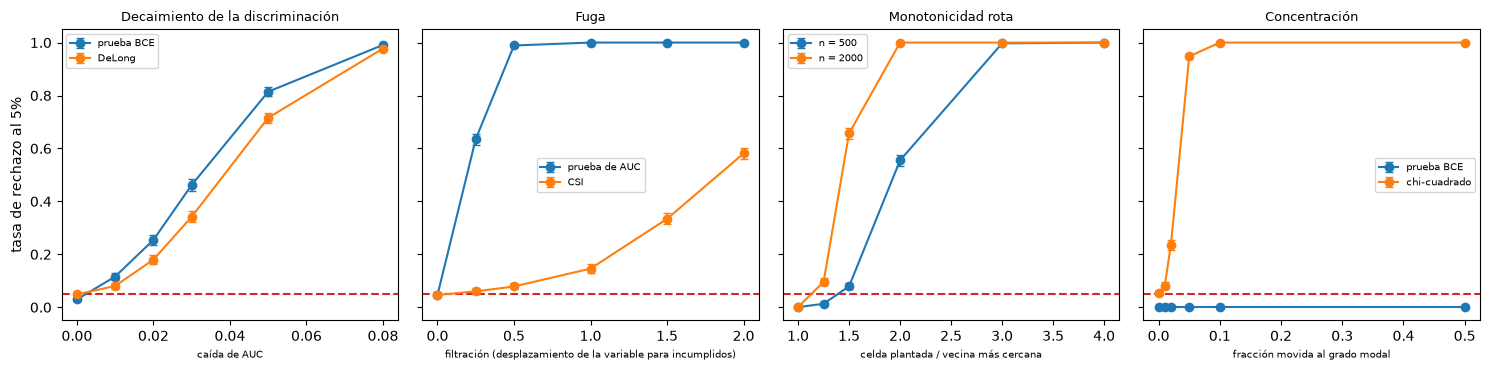

In [14]:
# Dibujar las curvas de potencia de las cuatro familias con intervalos de Wilson
panels = (
    ("Decaimiento de la discriminación", "discrimination-decay", drops, "d", (("disc.auc_vs_initial", "prueba BCE"), ("disc.delong", "DeLong")), decay["outputs"]["ladder"]["label"][LANG]),
    ("Fuga", "leakage", leaks, "l", (("disc.auc_vs_initial", "prueba de AUC"), ("stability.csi", "CSI")), leak["outputs"]["ladder"]["label"][LANG]),
    ("Monotonicidad rota", "broken-monotonicity", ratios, "r", (("rating.migration_ztests", None),), mono["outputs"]["ladder"]["label"][LANG]),
    ("Concentración", "concentration", moved, "c", (("rating.hhi", "prueba BCE"), ("stability.chi2", "chi-cuadrado")), conc["outputs"]["ladder"]["label"][LANG]),
)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, (title, family, ladder_values, letter, tests, xlabel) in zip(axes, panels):
    for index, (test, label) in enumerate(tests):
        if family == "broken-monotonicity":
            series = [(f"{test}@r{{x:g}}-n{n}", f"n = {n}") for n in (500, 2000)]
        else:
            series = [(f"{test}@{letter}{{x:g}}", label)]
        for k, (pattern, name) in enumerate(series):
            points = [rows[family][pattern.format(x=x)]["rates"]["p<0.05"] for x in ladder_values]
            rate = np.array([p["rate"] for p in points])
            low = np.array([p["wilson_low"] for p in points])
            high = np.array([p["wilson_high"] for p in points])
            ax.errorbar(ladder_values, rate, yerr=[rate - low, high - rate], fmt="o-", capsize=3, color=f"C{index + k}", label=name)
    ax.axhline(0.05, color="tab:red", linestyle="--")
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(xlabel, fontsize=7)
    ax.legend(fontsize=7)
axes[0].set_ylabel("tasa de rechazo al 5%")
fig.tight_layout()
plt.show()

## Resultados

- **Decaimiento: una caída de 5 puntos de AUC se detecta cuatro veces de cada cinco, y de 2 puntos una vez de cada cuatro.** Con 150 incumplidos, la prueba del BCE dispara 11,6% de las veces con una caída de 0,01, 25,5% con 0,02, 46,2% con 0,03, 81,5% con 0,05 y 99,1% con 0,08; DeLong dispara 8,1%, 18,0%, 34,2%, 71,6% y 97,8%. Interpolada, 80% de potencia necesita una caída de 0,0492 para la prueba del BCE y una brecha de 0,0596 para DeLong, que compara dos AUC estimados y no una estimación con un número. Sin caída la prueba del BCE rechaza 2,9% en esta escalera, y 3,4% y 4,2% en las otras dos filas de los artefactos con AUC de desarrollo conocido (cuaderno 02 y Parte A, paso 3): un tamaño igual o algo menor que 5%, no mayor. En un conjunto del peldaño 0,05 la prueba del BCE dio un AUC estimado de 0,734 (la verdad es 0,75), S = 3,20 y p = 0,0007, y DeLong p = 0,015.
- **Decaimiento: el AUC de desarrollo es una estimación, y la forma del BCE la ignora.** Sin ningún cambio, la forma del BCE rechaza 4,2% cuando el AUC de desarrollo es conocido, 11,2% cuando se estimó con una muestra tan grande como la actual, y 17,0% cuando la muestra actual es 2,14 veces la de desarrollo (la razón de los tramos de C01). Sumar la varianza de desarrollo lleva esos dos a 5,6% y 5,3%. La repetición de la forma extendida da exactamente el conteo versionado (223).
- **Fuga: la prueba de AUC la ve, el CSI de la variable filtrada apenas.** Una fuga de 0,5 infla el AUC de desarrollo en 0,082 y la prueba de AUC dispara 98,9% de las veces; el CSI de la variable filtrada dispara 7,9%, y 14,6% con una fuga de 1, que infla el AUC en 0,150. La distribución propia de la variable se mueve muy poco para alarmar a un índice de estabilidad: la fuga se muestra como una caída de discriminación fuera de tiempo, no como deriva en el insumo.
- **Fuga: DeLong en modelos anidados casi nunca rechaza.** La repetición da 2 rechazos en 1.000 al nivel de 5%, frente al 0,001 de Demler et al. (z = 0,58, concordancia), y para puntajes no anidados sobre una muestra independiente la prueba rechaza 5,25% (EE 0,50 puntos). Comparar un modelo con una versión de sí mismo con un predictor extra, sobre la muestra a la que ambos se ajustaron, no es para lo que se construyó la prueba.
- **Monotonicidad: la celda plantada se encuentra, pero no a menudo con 500 por grado.** Una celda del doble de su vecina más cercana (0,114 frente a 0,057) se encontró en una muestra con un z de -4,27 y un valor p ajustado por Holm de 0,0004, pero a lo largo de las repeticiones la prueba dispara 55,5% de las veces con esa razón y 500 deudores por grado, 7,9% con 1,5 y 1,3% con 1,25, y 100%, 65,7% y 9,6% con 2.000. Sin defecto rechaza 0,1%: el control de Holm sobre 42 celdas la vuelve conservadora. La repetición de la fila de razón 2 da 1.110, el conteo versionado.
- **Monotonicidad: las PD cruzadas las ve tanto la prueba de forma como el chi-cuadrado.** Con los grados 3 y 4 intercambiados, la prueba del perfil dispara 95,2% y el chi-cuadrado por grados 93,7%; a mitad de camino, 53,6% y 49,3%. La prueba del perfil, ciega a un nivel uniforme (cuaderno 03), ve un cambio de orden.
- **Concentración: el estadístico del BCE no puede rechazar con estos diez grados.** Las frecuencias de desarrollo tienen un coeficiente de variación de 0,602. Evaluado con el motor sobre 401 fracciones, el estadístico llega a un máximo de 1,0913 (con una fracción de 0,3725), el resultado principal versionado, y da un menor valor p de 0,138; con toda la masa en el grado modal vale 0,778, menos. El valor crítico al 5% es 1,645, así que la prueba del BCE rechazó 0% de las veces en cada peldaño, incluida la mitad de la masa movida. De las cuatro configuraciones guardadas, el estadístico supera 1,645 solo con diez grados y un CV inicial de 0,3 (1,756) y con veintiséis grados y 0,6 (1,823).
- **Una prueba sobre los conteos ve lo que el estadístico acotado no puede.** El chi-cuadrado de homogeneidad sobre los conteos por grado rechaza 5,3% sin nada movido, 23,4% con 2% movido y 94,8% con 5% movido, frente a 0% de la prueba del BCE en todo momento.

Lo que este cuaderno no muestra: la potencia con tamaños de muestra distintos de los de las escaleras, ni con defectos distintos de los plantados. La repetición de DeLong depende del diseño del generador de Demler et al. (un solo predictor agregado sin efecto). Un estadístico acotado es una propiedad de la fórmula de esta prueba para estas frecuencias, no un veredicto sobre el deseo del BCE de vigilar la concentración.

## Resumen

- La prueba de AUC del BCE detecta una caída de 5 puntos de AUC con 80% de potencia sobre 150 incumplidos, y una brecha de 6 puntos con DeLong; una caída de 2 puntos pasa inadvertida tres veces de cada cuatro.
- La prueba del BCE trata el AUC de desarrollo como un número conocido: cuando se estimó con una muestra tan grande como la actual, la prueba rechaza 11,2% de las veces sin ningún cambio, y 5,6% cuando se suma su varianza.
- Una fuga se muestra como una caída de discriminación fuera de tiempo (prueba de AUC 98,9% con una fuga de 0,5) y apenas como deriva en la variable (CSI 7,9%); DeLong en modelos anidados ajustados con una muestra rechaza 2 de 1.000 veces, como encontraron Demler et al.
- Las pruebas z de migración encuentran una celda del doble de su vecina 55,5% de las veces con 500 deudores por grado y siempre con 2.000; la prueba del perfil de incumplimiento ve un cruce de dos PD que no puede ver en un nivel uniforme.
- El estadístico de concentración del BCE llega a 1,0913 con estos diez grados, bajo el 1,645 que necesita, de modo que nunca rechaza; el chi-cuadrado de los conteos rechaza 94,8% de las veces con 5% de la masa movida.

**Qué probar a continuación.** Reconstruye la configuración de concentración con veintiséis grados (`GradeFrequencies`, `concentrate`) y encuentra la fracción en que el estadístico del BCE supera por primera vez 1,645; luego lee el cuaderno 07, que pone estas mediciones junto a la literatura.

## Referencias

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, secciones 2.5.4.1, 2.5.5.2 y 2.5.5.3 y Anexo 3.1 (el AUC frente al AUC inicial, las pruebas z de migración, la prueba de concentración). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Hanley, J. A. y McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- Demler, O. V., Pencina, M. J. y D'Agostino, R. B. Sr (2012), Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23). https://doi.org/10.1002/sim.5328
- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4): la prueba del perfil de incumplimiento. https://doi.org/10.21314/jcr.2013.169
- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Este repositorio: `docs/design/features/c22-validator/requirements.md` y `data-pipeline/pipeline/cases/c22_validator.py`, que escribió los artefactos.